In [13]:
## Import modules
# for Data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
# from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
# for Model
import tensorflow as tf
from tensorflow import keras
import tensorflow.keras                             # type: ignore
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
# for Other
import os

import cv2
from tqdm import tqdm
import io
import seaborn as sns

In [15]:
# Specify the path to the main data folder
cwd = os.getcwd()
train_path = os.path.join(cwd, "mri_alz_prog_CNN", "Reduced-Alzheimers-ADNI", "train")
test_path = os.path.join(cwd, "mri_alz_prog_CNN", "Reduced-Alzheimers-ADNI", "test")

train_datagen = ImageDataGenerator(
    validation_split=0.2  # 20% validation split
)
'''
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # Use a preprocessing function appropriate for your model (e.g., ResNet, Inception)
    zoom_range=0.1,  # Small zoom for slight variations
    rotation_range=3,  # Small rotations, as large rotations are not realistic for MRIs
    fill_mode='nearest',  # To handle pixels introduced during transformations
    horizontal_flip=True,  # Horizontal flipping is generally safe for brain MRIs
    vertical_flip=False,  # Avoid vertical flipping as it could distort anatomical structure
    validation_split=0.2  # 20% validation split
)
'''
'''
train_datagen=ImageDataGenerator(preprocessing_function=preprocess_input,
                                 shear_range = 0.15,
                                 zoom_range =.15,
                                 rotation_range =5,
                                 fill_mode='nearest',
                                 validation_split=0.2  # 20% validation split
                                 )
'''

# Create train_generator iterator object
train_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='training',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Create train_generator iterator object
val_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 subset='validation',
                                                 shuffle=True)   # set to False to show images in the same order for display

# Test data generator
test_datagen = ImageDataGenerator(rescale=1./255)  # Only rescaling, no augmentation

# Test generator
test_generator = test_datagen.flow_from_directory(
    test_path, 
    target_size=(256, 256),
    color_mode='rgb',
    batch_size=16,
    seed=1,
    class_mode='categorical',
    shuffle=False  # Do not shuffle to keep predictions in order
)


Found 538 images belonging to 5 classes.
Found 134 images belonging to 5 classes.
Found 672 images belonging to 5 classes.


In [17]:
labels = ['Reduced AD','Reduced CN', 'Reduced EMCI', 'Reduced LMCI','Reduced MCI']

X_train = []  # Training Dataset
Y_train = []  # Training Labels
image_size = 150

cwd = os.getcwd()  # Current working directory

for i in labels:
    folderPath = os.path.join(cwd, "mri_alz_prog_CNN", "Reduced-Alzheimers-ADNI", "train", i)
    for j in tqdm(os.listdir(folderPath)):
        image_path = os.path.join(folderPath, j)
        image = cv2.imread(image_path)
        if image is None:
            print(f"Warning: Unable to load image at {image_path}")
            continue
        image = cv2.resize(image, (image_size, image_size))
        X_train.append(image)
        Y_train.append(i)

# Convert lists to numpy arrays
Xtrain = np.array(X_train)
Ytrain = np.array(Y_train)

X_test = []  # Test Dataset
Y_test = []  # Training Labels
image_size = 150

cwd = os.getcwd()  # Current working directory

for i in labels:
    folderPath = os.path.join(cwd, "mri_alz_prog_CNN", "Reduced-Alzheimers-ADNI", "test", i)
    for j in tqdm(os.listdir(folderPath)):
        image_path = os.path.join(folderPath, j)
        image = cv2.imread(image_path)
        if image is None:
            print(f"Warning: Unable to load image at {image_path}")
            continue
        image = cv2.resize(image, (image_size, image_size))
        X_test.append(image)
        Y_test.append(i)

# Convert lists to numpy arrays
Xtest = np.array(X_test)
Ytest = np.array(Y_test)

print(f"Final train dataset size: {Xtrain.shape}, Labels: {Ytrain.shape}")
print(f"Final test dataset size: {Xtest.shape}, Labels: {Ytest.shape}")

100%|███████████████████████████████████████████████████████████████████████████████| 150/150 [00:01<00:00, 100.37it/s]

Final train dataset size: (672, 150, 150, 3), Labels: (672,)
Final test dataset size: (672, 150, 150, 3), Labels: (672,)


In [23]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Flatten, TimeDistributed, LSTM
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Encode labels to integers
label_encoder = LabelEncoder()
Ytrain_encoded = label_encoder.fit_transform(Ytrain)
Ytest_encoded = label_encoder.transform(Ytest)

# Convert labels to one-hot encoding
Ytrain_onehot = to_categorical(Ytrain_encoded)
Ytest_onehot = to_categorical(Ytest_encoded)

# Reshape image data to treat each row as a sequence
# Assuming images are already normalized
Xtrain_rnn = Xtrain.reshape(Xtrain.shape[0], image_size, image_size * 3)  # Flatten columns in each row
Xtest_rnn = Xtest.reshape(Xtest.shape[0], image_size, image_size * 3)

# RNN Model
model = Sequential()
model.add(LSTM(128, input_shape=(image_size, image_size * 3), return_sequences=True))
model.add(LSTM(64, return_sequences=False))  # Final LSTM layer returns the sequence
model.add(Dense(32, activation='relu'))
model.add(Dense(len(labels), activation='softmax'))  # Output layer with number of classes

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the RNN model
history = model.fit(
    Xtrain_rnn, Ytrain_onehot,
    validation_data=(Xtest_rnn, Ytest_onehot),
    epochs=50,
    batch_size=16
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(Xtest_rnn, Ytest_onehot)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")


Epoch 1/50


C:\Users\alexh\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


42/42 ━━━━━━━━━━━━━━━━━━━━ 10s 116ms/step - accuracy: 0.3018 - loss: 1.5428 - val_accuracy: 0.2381 - val_loss: 1.6412
Epoch 2/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.4734 - loss: 1.3445 - val_accuracy: 0.2738 - val_loss: 1.6683
Epoch 3/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.4532 - loss: 1.2535 - val_accuracy: 0.2634 - val_loss: 1.8059
Epoch 4/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.5249 - loss: 1.1495 - val_accuracy: 0.2738 - val_loss: 1.7966
Epoch 5/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.6069 - loss: 1.0447 - val_accuracy: 0.2872 - val_loss: 1.8528
Epoch 6/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.5823 - loss: 0.9969 - val_accuracy: 0.3259 - val_loss: 1.8655
Epoch 7/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.6276 - loss: 0.9015 - val_accuracy: 0.2976 - val_loss: 1.8668
Epoch 8/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step - accuracy: 0.6061 - loss: 0.9539 - val_accuracy: 0.3140 - val

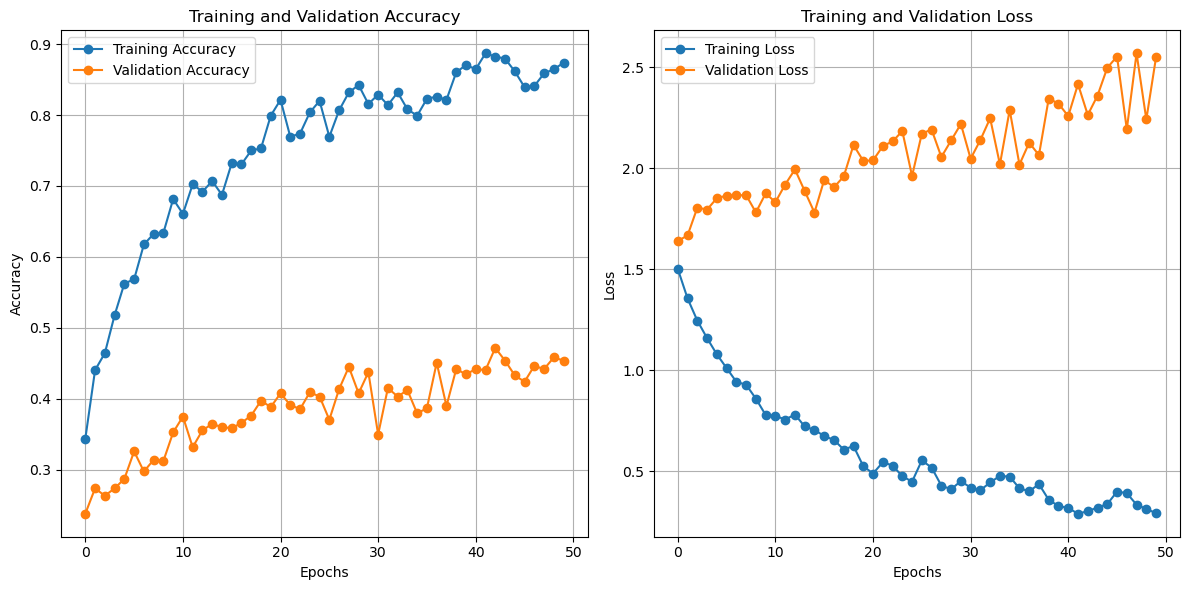

In [24]:
# Extracting values from the history object
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Plotting Accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(train_accuracy, label='Training Accuracy', marker='o')
plt.plot(val_accuracy, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plotting Loss
plt.subplot(1, 2, 2)
plt.plot(train_loss, label='Training Loss', marker='o')
plt.plot(val_loss, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()